# Notebook 02: Limpieza y exploración

**Objetivo:** preparar la cartera para el análisis y responder las primeras preguntas de negocio:
¿cómo evolucionó el default según el año de originación? ¿La calificación de Lending Club ordena bien el riesgo?

**Base:** 589.488 préstamos a 36 meses originados entre 2012 y 2015, con resultado final conocido (ver notebook 01).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/prestamos_36m_2012_2015.csv", parse_dates=["issue_d"])
print(df.shape)

(589488, 20)


In [2]:
print(df.dtypes)
df.describe().round(2)

loan_amnt                     float64
term                              str
int_rate                      float64
grade                             str
sub_grade                         str
emp_length                        str
home_ownership                    str
annual_inc                    float64
verification_status               str
issue_d                datetime64[us]
loan_status                       str
purpose                           str
addr_state                        str
dti                           float64
delinq_2yrs                   float64
fico_range_low                float64
revol_util                    float64
total_pymnt                   float64
recoveries                    float64
default                         int64
dtype: object


,loan_amnt,int_rate,annual_inc,issue_d,dti,delinq_2yrs,fico_range_low,revol_util,total_pymnt,recoveries,default
count,589488.00,589488.00,589488.00,589488,589486.00,589488.00,589488.00,589188.00,589488.00,589488.00,589488.00
mean,12638.48,12.06,72824.71,2014-08-29 21:24:13.660125,17.79,0.32,694.11,54.04,13679.49,129.62,0.14
min,1000.00,5.32,0.00,2012-01-01 00:00:00,0.00,0.00,660.00,0.00,0.00,0.00,0.00
25%,7000.00,8.90,43000.00,2014-01-01 00:00:00,11.55,0.00,670.00,36.60,6905.41,0.00,0.00
50%,10000.00,12.05,60000.00,2014-11-01 00:00:00,17.25,0.00,685.00,54.60,11451.38,0.00,0.00
75%,16500.00,14.49,87600.00,2015-07-01 00:00:00,23.60,0.00,710.00,72.20,18121.30,0.00,0.00
max,35000.00,28.99,9000000.00,2015-12-01 00:00:00,999.00,30.00,845.00,892.30,51912.52,34294.10,1.00
std,7819.88,3.88,66388.43,NaN,8.40,0.88,30.52,23.61,9080.01,634.48,0.35


In [3]:
print("Ingreso = 0:", (df["annual_inc"] == 0).sum())
print("Ingreso > 1 millón:", (df["annual_inc"] > 1_000_000).sum())
print("DTI > 40:", (df["dti"] > 40).sum())
print("DTI = 999:", (df["dti"] == 999).sum())
print("Uso de tarjetas > 100%:", (df["revol_util"] > 100).sum())
print("Total pagado = 0:", (df["total_pymnt"] == 0).sum())

Ingreso = 0: 2
Ingreso > 1 millón: 103
DTI > 40: 34
DTI = 999: 1
Uso de tarjetas > 100%: 2203
Total pagado = 0: 94


In [4]:
df["dti"] = df["dti"].replace(999, float("nan"))

sin_pagos = df[df["total_pymnt"] == 0]
print("Préstamos sin ningún pago:", len(sin_pagos))
print("De ellos, en default:", sin_pagos["default"].sum())

Préstamos sin ningún pago: 94
De ellos, en default: 94


## Decisiones de limpieza

- **DTI = 999 (1 caso):** es un código de "sin dato", no un valor real. Se convirtió en nulo y se completó con la mediana.
- **Nulos en `revol_util` (300) y `dti` (2):** se completaron con la mediana, que no se distorsiona por valores extremos.
- **Nulos en `emp_length` (35.330, ≈6%):** no se borraron. Se marcaron como "Sin dato" para evaluar si el faltante es una señal de riesgo.
- **Valores extremos de ingreso (105 casos) y uso de tarjetas > 100% (2.203 casos):** se mantienen. Representan menos del 0,4% de la cartera y no alteran las tasas de default. El análisis por ingreso se hace por tramos.
- **Préstamos sin ningún pago (94, 0,02%):** todos terminaron en default, lo que confirma la consistencia de los datos. En una operación real este grupo se monitorea como posible fraude.

**Hallazgos sobre la política de crédito:** no hay préstamos con score FICO menor a 660 y solo 34 superan un DTI de 40%. Lending Club aplicaba un score mínimo y un tope de endeudamiento. Los datos incluyen solo clientes aprobados (sesgo de selección): las conclusiones valen para esa población.


In [5]:
df["emp_length"] = df["emp_length"].fillna("Sin dato")

for col in ["revol_util", "dti"]:
    df[col] = df[col].fillna(df[col].median())

print("Nulos restantes:", df.isna().sum().sum())

Nulos restantes: 0


In [6]:
df["anio"] = df["issue_d"].dt.year
df["anio"].value_counts().sort_index()


anio
2012     43470
2013    100422
2014    162570
2015    283026
Name: count, dtype: int64

In [7]:
por_anio = df.groupby("anio").agg(prestamos=("default", "size"), tasa_default=("default", "mean"))
por_anio["tasa_default"] = (por_anio["tasa_default"] * 100).round(2)
por_anio

,prestamos,tasa_default
anio,,
2012,43470,13.58
2013,100422,12.33
2014,162570,13.73
2015,283026,14.89


In [8]:
por_grade = df.groupby("grade").agg(prestamos=("default", "size"), tasa_default=("default", "mean"), tasa_interes=("int_rate", "mean"))
por_grade["tasa_default"] = (por_grade["tasa_default"] * 100).round(2)
por_grade["tasa_interes"] = por_grade["tasa_interes"].round(2)
por_grade

,prestamos,tasa_default,tasa_interes
grade,,,
A,133261,5.45,7.21
B,202303,11.22,10.86
C,156060,18.03,13.94
D,72814,23.57,17.26
E,20535,28.92,19.98
F,4052,33.14,23.90
G,463,40.17,26.27


In [9]:
por_antiguedad = df.groupby("emp_length")["default"].agg(["size", "mean"])
por_antiguedad["mean"] = (por_antiguedad["mean"] * 100).round(2)
por_antiguedad.sort_values("mean", ascending=False)

,size,mean
emp_length,,
Sin dato,35330,20.52
< 1 year,47795,14.66
1 year,39094,14.49
8 years,29174,14.08
3 years,47348,14.07
2 years,53446,14.04
4 years,35030,14.03
9 years,22467,13.97
5 years,37131,13.92


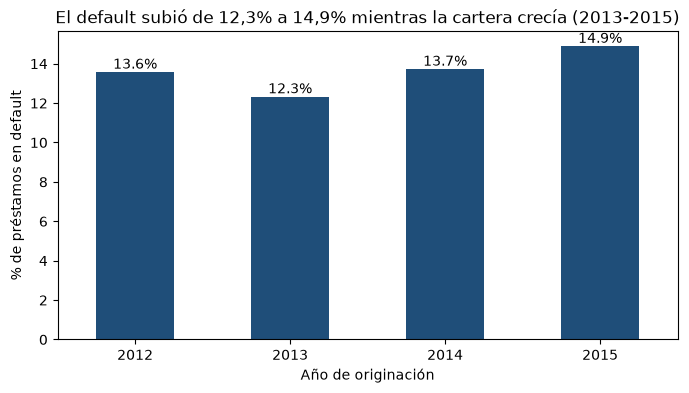

In [10]:
ax = por_anio["tasa_default"].plot(kind="bar", color="#1f4e79", figsize=(8, 4))
ax.set_title("El default subió de 12,3% a 14,9% mientras la cartera crecía (2013-2015)")
ax.set_xlabel("Año de originación")
ax.set_ylabel("% de préstamos en default")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.xticks(rotation=0)
plt.show()

## Primeros hallazgos

1. **Crecimiento con deterioro:** la cartera pasó de 43.470 préstamos en 2012 a 283.026 en 2015 (x6,5), y el default subió de 12,33% (2013) a 14,89% (2015). Hipótesis: la política de aprobación se flexibilizó para crecer. Pendiente: verificar si cambió la mezcla de calificaciones por año.
2. **La calificación ordena bien el riesgo:** el default sube de forma monótona de 5,45% (A) a 40,17% (G). A, B y C concentran el 83% de la cartera.
3. **Señal de alerta en el precio:** desde la calificación B, el default crece más rápido que la tasa de interés. No es una conclusión: la tasa es anual, el default es acumulado y un préstamo en default no pierde todo el capital. La rentabilidad real se mide en el notebook 03.
4. **El faltante de antigüedad laboral es una señal de riesgo:** los clientes sin dato tienen 20,52% de default contra 14,03% del promedio. Entre 1 y 9 años de antigüedad el default casi no varía (13,8% a 14,7%). Pendiente: verificar si el efecto se mantiene dentro de cada calificación.